<a href="https://colab.research.google.com/github/adamarsyadfaizin/Pembelajaran-Mesin_2026_3F/blob/main/JS08/JS08-TUGAS02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
import hdbscan
iris = load_iris()
X = iris.data
y_true = iris.target
feature_names = iris.feature_names
target_names = iris.target_names
print("Jumlah sampel:", X.shape[0])
print("Jumlah fitur:", X.shape[1])
print("Fitur:", feature_names)
print("Label asli:", list(target_names))

Jumlah sampel: 150
Jumlah fitur: 4
Fitur: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Label asli: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=5,
    min_samples=5,
    metric="euclidean",
    cluster_selection_method="eom"
)
labels = clusterer.fit_predict(X_scaled)
cluster_ids = sorted(set(labels) - {-1})
n_clusters = len(cluster_ids)
n_noise = int(np.sum(labels == -1))
print("Jumlah cluster yang terbentuk:", n_clusters)
print("Jumlah noise:", n_noise)
print("Persentase noise: {:.2f}%".format(n_noise / len(labels) * 100))
print("\nJumlah data per cluster (label -1 adalah noise):")
display(pd.Series(labels, name="Cluster").value_counts().sort_index().to_frame())

Jumlah cluster yang terbentuk: 2
Jumlah noise: 2
Persentase noise: 1.33%
\nJumlah data per cluster (label -1 adalah noise):


,count
Cluster,
-1,2
0,99
1,49


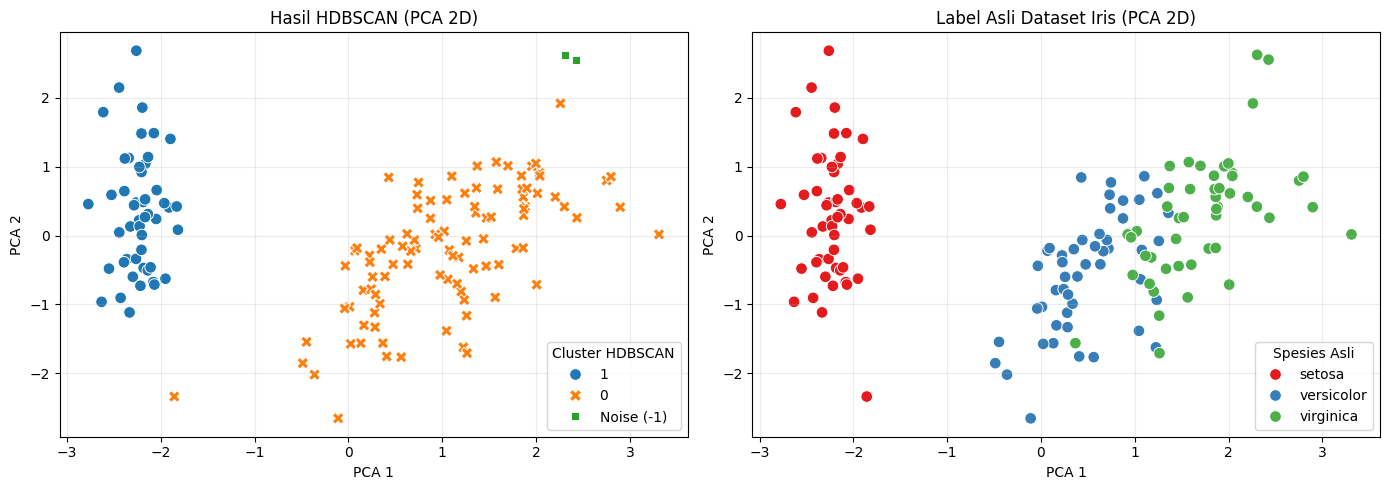

Variansi yang dijelaskan PCA 2D: 95.81%


In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
plot_df = pd.DataFrame({
    "PCA 1": X_pca[:, 0],
    "PCA 2": X_pca[:, 1],
    "Cluster HDBSCAN": labels.astype(str),
    "Spesies Asli": [target_names[i] for i in y_true]
})
plot_df.loc[labels == -1, "Cluster HDBSCAN"] = "Noise (-1)"
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(
    data=plot_df, x="PCA 1", y="PCA 2",
    hue="Cluster HDBSCAN", style="Cluster HDBSCAN",
    palette="tab10", s=70, ax=axes[0]
)
axes[0].set_title("Hasil HDBSCAN (PCA 2D)")
axes[0].grid(alpha=0.25)
sns.scatterplot(
    data=plot_df, x="PCA 1", y="PCA 2",
    hue="Spesies Asli", palette="Set1", s=70, ax=axes[1]
)
axes[1].set_title("Label Asli Dataset Iris (PCA 2D)")
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()
print("Variansi yang dijelaskan PCA 2D: {:.2f}%".format(
    pca.explained_variance_ratio_.sum() * 100
))

In [ ]:
ari = adjusted_rand_score(y_true, labels)
nmi = normalized_mutual_info_score(y_true, labels)
print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Normalized Mutual Information (NMI): {nmi:.4f}")
comparison = pd.crosstab(
    pd.Series([("Noise (-1)" if v == -1 else f"Cluster {v}") for v in labels],
              name="Hasil HDBSCAN"),
    pd.Series([target_names[v] for v in y_true], name="Spesies Asli")
)
display(comparison)

Adjusted Rand Index (ARI): 0.5394
Normalized Mutual Information (NMI): 0.6778


Spesies Asli,setosa,versicolor,virginica
Hasil HDBSCAN,,,
Cluster 0,1,50,48
Cluster 1,49,0,0
Noise (-1),0,0,2


### KESIMPULAN

1. Analisis ini menggunakan data bunga Iris yang mencakup 150 baris data serta 4 karakteristik utama.
2. Berdasarkan algoritma HDBSCAN, terbentuk sebanyak 2 kelompok (cluster) data.
3. Teridentifikasi hanya ada 2 data pencilan (noise) dari keseluruhan 150 sampel yang diuji.
4. Evaluasi menunjukkan nilai ARI sebesar 0.5394 dan NMI sebesar 0.6778, menandakan bahwa hasil pengelompokan memiliki korelasi tingkat menengah dengan spesies aktual.
5. Spesies asli sama sekali tidak dilibatkan selama proses clustering, melainkan murni difungsikan sebagai tolok ukur validasi hasil akhir.